In [94]:
import numpy as np
import matplotlib.pyplot as plt
import random
from PIL import Image

n = 784
def psi(x):
    return np.tanh(5*x)

def distort(img_vector, percent):
    img_array = np.array(img_vector, dtype=np.float32)
    num_randomized = round(percent * n)
    to_randomize = random.sample(range(n), num_randomized)
    randomized_values = np.random.uniform(-1, 1, num_randomized)
    img_array[to_randomize] = randomized_values
    return img_array.tolist()


In [95]:
def to_image(img_vector, label):
    img_vector = np.array(img_vector)
    img_vector = np.where(img_vector >= 0, 1.0, 0.0)
    start_Img = img_vector.reshape(28, 28)
    plt.imshow(start_Img, cmap="gray")
    plt.title(f"{label}", fontsize=14, fontweight="bold", pad=15)
    plt.axis("off")
    plt.show()

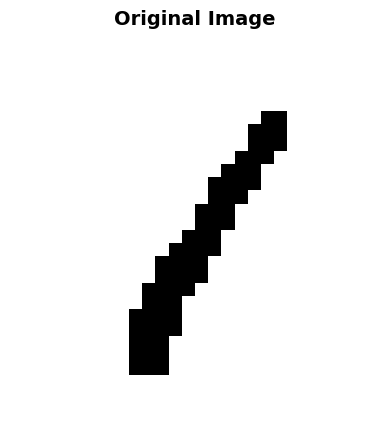

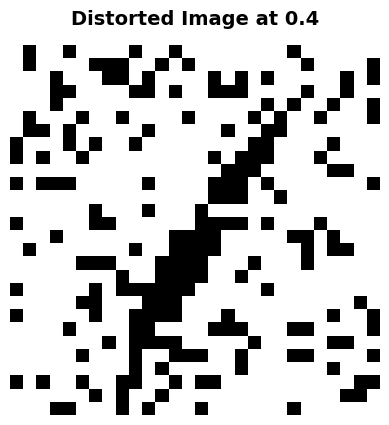

In [96]:
import pandas as pd
ds = pd.read_csv("basic-memory-ds/mnist_processed.csv")
test_img = df.iloc[0].to_numpy()

to_image(test_img, "Original Image")

distorted_img = distort(test_img, 0.4)
to_image(distorted_img, "Distorted Image at 0.4")

In [106]:
def matrix(ds, flat_img):
    alpha = (ds @ flat_img)
    w = (ds.T * alpha) @ ds 
    w = w.to_numpy()
    np.fill_diagonal(w, 0)
    w /= n
    return w

In [107]:
def euler_step(w, x0, dt=0.1, iters=50):
    x = np.array(x0) 
    for _ in range(iters):
        x = x + dt * (-x + w @ psi(x))
    return x

In [108]:
def classify(pattern, ds):
    scores = ds @pattern
    return int(np.argmax(scores)), scores

In [109]:
def random_start_recall(w, flat_img, rng, dt=0.1, iters=50):
    x0 = rng.normal(0, 0.01, n)
    settled_state = euler_step(w, x0, dt=dt, iters=iters)

/var/folders/nc/nl156vjs2rbd6prvhcvcsdt00000gn/T/ipykernel_7853/1394861784.py:4: RuntimeWarning: divide by zero encountered in matmul
  x = x + dt * (-x + w @ psi(x))
/var/folders/nc/nl156vjs2rbd6prvhcvcsdt00000gn/T/ipykernel_7853/1394861784.py:4: RuntimeWarning: overflow encountered in matmul
  x = x + dt * (-x + w @ psi(x))
/var/folders/nc/nl156vjs2rbd6prvhcvcsdt00000gn/T/ipykernel_7853/1394861784.py:4: RuntimeWarning: invalid value encountered in matmul
  x = x + dt * (-x + w @ psi(x))


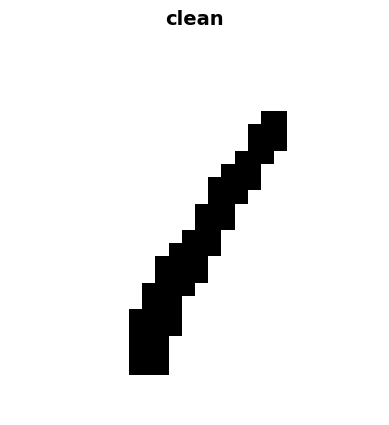

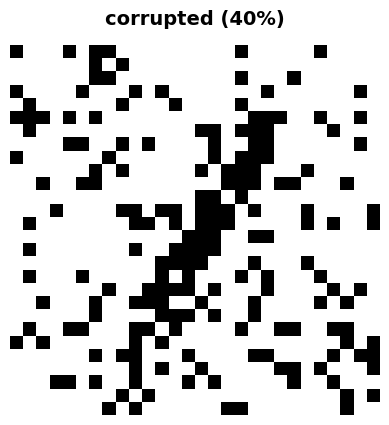

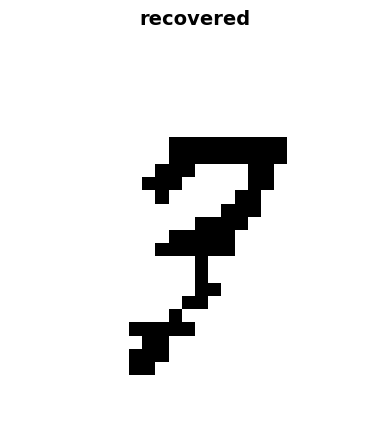

In [111]:
rng = np.random.default_rng(0)

target_digit = 1
clean = ds.iloc[0].to_numpy()
corrupted = distort(clean, percent=0.4)

w = matrix(ds, corrupted)
recovered = euler_step(w, corrupted)

pred, scores = classify(recovered, ds)

to_image(clean, "clean")
to_image(corrupted, "corrupted (40%)")
to_image(recovered, "recovered")

random_start_recall(w, corrupted, rng)